In [0]:
spark

In [0]:
from pyspark.sql import SparkSession

In [0]:
spark = SparkSession.builder.appName("Project").getOrCreate()

In [0]:
%sql
CREATE CATALOG IF NOT EXISTS my_catalog;

In [0]:
%sql
CREATE SCHEMA IF NOT EXISTS my_catalog.my_schema;

In [0]:
%sql
CREATE VOLUME IF NOT EXISTS my_catalog.my_schema.my_volume;


In [0]:
# Verifying if the file exists
dbutils.fs.ls("dbfs:/Volumes/my_catalog/my_schema/my_volume/")

[FileInfo(path='dbfs:/Volumes/my_catalog/my_schema/my_volume/car_prices.csv', name='car_prices.csv', size=88047552, modificationTime=1773490422000),
 FileInfo(path='dbfs:/Volumes/my_catalog/my_schema/my_volume/clean_data/', name='clean_data/', size=0, modificationTime=1776255463259),
 FileInfo(path='dbfs:/Volumes/my_catalog/my_schema/my_volume/instagram_usage_lifestyle.csv', name='instagram_usage_lifestyle.csv', size=439686262, modificationTime=1774057243000)]

In [0]:
# Reading the CSV File into Spark
df = spark.read.csv(
    "dbfs:/Volumes/my_catalog/my_schema/my_volume/instagram_usage_lifestyle.csv",
    header=True,
    inferSchema=True
)

In [0]:
# Data Understanding & Cleaning
df.printSchema()


root
 |-- user_id: integer (nullable = true)
 |-- app_name: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- country: string (nullable = true)
 |-- urban_rural: string (nullable = true)
 |-- income_level: string (nullable = true)
 |-- employment_status: string (nullable = true)
 |-- education_level: string (nullable = true)
 |-- relationship_status: string (nullable = true)
 |-- has_children: string (nullable = true)
 |-- exercise_hours_per_week: double (nullable = true)
 |-- sleep_hours_per_night: double (nullable = true)
 |-- diet_quality: string (nullable = true)
 |-- smoking: string (nullable = true)
 |-- alcohol_frequency: string (nullable = true)
 |-- perceived_stress_score: integer (nullable = true)
 |-- self_reported_happiness: integer (nullable = true)
 |-- body_mass_index: double (nullable = true)
 |-- blood_pressure_systolic: integer (nullable = true)
 |-- blood_pressure_diastolic: integer (nullable = true)
 |-- daily_st

In [0]:
df.show(5)

+-------+---------+---+----------+--------------+-----------+------------+------------------+---------------+-------------------+------------+-----------------------+---------------------+------------+-------+-----------------+----------------------+-----------------------+---------------+-----------------------+------------------------+-----------------+-----------------+-------------+-----------------------+-------------------+-------------------------+-------------------------+------------------------------+----------------+----------------------+---------------------+----------------------+-------------------+------------------------+-----------------+---------------------+------------------+-------------------+--------------------+-----------------------+------------------------+---------------------+---------------+---------------+---------------------+--------------------------+---------------------+---------------+------------------------------+-----------------------+---------

In [0]:
# Basic Overview
print("Row count:", df.count())
print("Column count:", len(df.columns))

Row count: 1547896
Column count: 58


In [0]:
display(df)

user_id,app_name,age,gender,country,urban_rural,income_level,employment_status,education_level,relationship_status,has_children,exercise_hours_per_week,sleep_hours_per_night,diet_quality,smoking,alcohol_frequency,perceived_stress_score,self_reported_happiness,body_mass_index,blood_pressure_systolic,blood_pressure_diastolic,daily_steps_count,weekly_work_hours,hobbies_count,social_events_per_month,books_read_per_year,volunteer_hours_per_month,travel_frequency_per_year,daily_active_minutes_instagram,sessions_per_day,posts_created_per_week,reels_watched_per_day,stories_viewed_per_day,likes_given_per_day,comments_written_per_day,dms_sent_per_week,dms_received_per_week,ads_viewed_per_day,ads_clicked_per_day,time_on_feed_per_day,time_on_explore_per_day,time_on_messages_per_day,time_on_reels_per_day,followers_count,following_count,uses_premium_features,notification_response_rate,account_creation_year,last_login_date,average_session_length_minutes,content_type_preference,preferred_content_theme,privacy_setting_level,two_factor_auth_enabled,biometric_login_used,linked_accounts_count,subscription_status,user_engagement_score
1,Instagram,51,Female,India,Rural,High,Retired,Bachelor’s,Single,No,7.2,7.7,Good,No,Rarely,3,8,20.8,148,86,8107,49.9,3,4,7,4.3,0,5.0,1,3,42,28,28,5,12,12,4,1,2,1,1,2,374,647,No,0.34,2015,2025-11-02,5.0,Mixed,Tech,Private,Yes,No,0,Free,7.83
2,Instagram,64,Female,United Kingdom,Urban,Middle,Full-time employed,Other,Divorced,No,10.9,8.6,Very poor,No,Rarely,1,1,23.5,133,84,8059,15.6,0,5,10,4.7,2,74.0,5,3,78,54,68,15,18,10,11,1,31,19,16,19,2585,3511,No,0.56,2018,2025-03-22,14.8,Photos,Fashion,Public,No,No,3,Free,1.43
3,Instagram,41,Female,Canada,Urban,Middle,Student,Bachelor’s,In a relationship,No,5.0,6.7,Good,No,Rarely,4,10,28.6,135,88,7872,31.8,4,5,14,1.5,2,5.0,1,7,29,26,25,6,12,13,4,0,3,1,1,1,3414,6761,No,0.73,2011,2025-08-10,5.0,Mixed,Other,Public,Yes,Yes,1,Free,9.67
4,Instagram,27,Non-binary,South Korea,Urban,Middle,Unemployed,Master’s,In a relationship,No,10.6,6.5,Poor,Yes,Never,18,1,22.5,105,73,7801,43.4,2,3,13,3.3,4,233.0,9,5,241,109,132,36,31,32,33,3,108,64,52,64,617,1193,No,0.73,2019,2025-03-31,25.9,Stories,Tech,Private,No,No,1,Free,0.94
5,Instagram,55,Male,India,Urban,Upper-middle,Full-time employed,Bachelor’s,Single,No,7.7,6.8,Average,No,Never,19,1,28.1,146,90,8005,50.2,2,2,12,4.5,3,184.0,14,5,146,113,103,36,29,37,20,5,78,55,22,55,1157,1072,Yes,0.65,2017,2025-03-19,13.1,Videos,Food,Public,Yes,No,0,Free,1.03
6,Instagram,20,Male,United States,Rural,Middle,Full-time employed,Bachelor’s,Married,Yes,5.2,5.8,Poor,No,Several times a week,1,3,25.7,138,71,7964,36.2,4,3,7,4.7,1,49.0,3,3,150,41,55,9,13,13,16,3,29,6,12,13,259,534,No,0.13,2013,2025-02-09,16.3,Photos,Food,Friends only,Yes,Yes,1,Free,1.64
7,Instagram,33,Non-binary,Japan,Urban,Lower-middle,Freelancer,High school,In a relationship,No,6.5,7.7,Poor,No,Never,23,10,24.5,114,72,7861,38.5,4,6,9,1.9,4,125.0,4,7,112,79,80,20,18,34,14,5,64,21,26,44,4373,8085,No,0.79,2012,2025-05-06,31.2,Photos,Tech,Friends only,Yes,No,3,Free,1.12
8,Instagram,51,Female,United Kingdom,Urban,Middle,Full-time employed,Other,Single,Yes,10.5,7.7,Average,No,Several times a week,33,3,20.3,118,85,7932,26.0,1,2,11,5.7,3,282.0,14,5,227,144,158,50,26,37,20,9,167,49,50,87,190,77,No,0.22,2014,2025-11-17,20.1,Videos,Travel,Public,No,No,2,Free,0.96
9,Instagram,31,Female,United Kingdom,Urban,Upper-middle,Retired,High school,Single,No,4.2,8.3,Poor,No,Rarely,12,6,22.2,93,98,8127,27.4,5,3,13,2.2,4,128.0,10,2,118,90,90,16,20,18,23,2,64,38,31,50,904,1129,No,0.98,2011,2025-05-10,12.8,Reels,Art,Public,Yes,Yes,2,Free,0.99
10,Instagram,35,Male,United States,Urban,Low,Student,High school,Married,No,2.1,6.5,Excellent,No,Rarely,25,10,23.3,128,75,8144,37.7,5,3,12,7.0,2,196.0,13,5,176,93,131,27,22,30,24,1,115,34,27,58,170,247,No,0.6,2011,2025-09-13,15.1,Reels,Tech,Friends only,Yes,No,1,Free,1.02


In [0]:
#Print Schema
df.printSchema()

root
 |-- user_id: integer (nullable = true)
 |-- app_name: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- country: string (nullable = true)
 |-- urban_rural: string (nullable = true)
 |-- income_level: string (nullable = true)
 |-- employment_status: string (nullable = true)
 |-- education_level: string (nullable = true)
 |-- relationship_status: string (nullable = true)
 |-- has_children: string (nullable = true)
 |-- exercise_hours_per_week: double (nullable = true)
 |-- sleep_hours_per_night: double (nullable = true)
 |-- diet_quality: string (nullable = true)
 |-- smoking: string (nullable = true)
 |-- alcohol_frequency: string (nullable = true)
 |-- perceived_stress_score: integer (nullable = true)
 |-- self_reported_happiness: integer (nullable = true)
 |-- body_mass_index: double (nullable = true)
 |-- blood_pressure_systolic: integer (nullable = true)
 |-- blood_pressure_diastolic: integer (nullable = true)
 |-- daily_st

In [0]:
#Identifying missing values
from pyspark.sql.functions import col, when, count
# Standard nulls
df.select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in df.columns
]).show()

+-------+--------+---+------+-------+-----------+------------+-----------------+---------------+-------------------+------------+-----------------------+---------------------+------------+-------+-----------------+----------------------+-----------------------+---------------+-----------------------+------------------------+-----------------+-----------------+-------------+-----------------------+-------------------+-------------------------+-------------------------+------------------------------+----------------+----------------------+---------------------+----------------------+-------------------+------------------------+-----------------+---------------------+------------------+-------------------+--------------------+-----------------------+------------------------+---------------------+---------------+---------------+---------------------+--------------------------+---------------------+---------------+------------------------------+-----------------------+----------------------

In [0]:
# cheking for Hidden Missing Values
from pyspark.sql.functions import trim, lower
missing_values = ["unknown", "n/a", "none", "", "null"]
for c in df.columns:
    df = df.withColumn(
        c,
        when(lower(trim(col(c))).isin(missing_values), None).otherwise(col(c))
    )

In [0]:
# Recheking Null values
df.select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in df.columns
]).show()

+-------+--------+---+------+-------+-----------+------------+-----------------+---------------+-------------------+------------+-----------------------+---------------------+------------+-------+-----------------+----------------------+-----------------------+---------------+-----------------------+------------------------+-----------------+-----------------+-------------+-----------------------+-------------------+-------------------------+-------------------------+------------------------------+----------------+----------------------+---------------------+----------------------+-------------------+------------------------+-----------------+---------------------+------------------+-------------------+--------------------+-----------------------+------------------------+---------------------+---------------+---------------+---------------------+--------------------------+---------------------+---------------+------------------------------+-----------------------+----------------------

In [0]:
# Finding duplicate rows (entire row duplicates)
df.groupBy(df.columns).count().filter("count > 1").show()

+-------+--------+---+------+-------+-----------+------------+-----------------+---------------+-------------------+------------+-----------------------+---------------------+------------+-------+-----------------+----------------------+-----------------------+---------------+-----------------------+------------------------+-----------------+-----------------+-------------+-----------------------+-------------------+-------------------------+-------------------------+------------------------------+----------------+----------------------+---------------------+----------------------+-------------------+------------------------+-----------------+---------------------+------------------+-------------------+--------------------+-----------------------+------------------------+---------------------+---------------+---------------+---------------------+--------------------------+---------------------+---------------+------------------------------+-----------------------+----------------------

In [0]:
total_duplicates = df.count() - df.dropDuplicates().count()
print(total_duplicates)
print(f"Total duplicates: {total_duplicates}")

0
Total duplicates: 0


In [0]:
# Checking data types
df.printSchema()

root
 |-- user_id: integer (nullable = true)
 |-- app_name: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- country: string (nullable = true)
 |-- urban_rural: string (nullable = true)
 |-- income_level: string (nullable = true)
 |-- employment_status: string (nullable = true)
 |-- education_level: string (nullable = true)
 |-- relationship_status: string (nullable = true)
 |-- has_children: string (nullable = true)
 |-- exercise_hours_per_week: double (nullable = true)
 |-- sleep_hours_per_night: double (nullable = true)
 |-- diet_quality: string (nullable = true)
 |-- smoking: string (nullable = true)
 |-- alcohol_frequency: string (nullable = true)
 |-- perceived_stress_score: integer (nullable = true)
 |-- self_reported_happiness: integer (nullable = true)
 |-- body_mass_index: double (nullable = true)
 |-- blood_pressure_systolic: integer (nullable = true)
 |-- blood_pressure_diastolic: integer (nullable = true)
 |-- daily_st

In [0]:
# Summary Statistics
df.describe().show()

+-------+-----------------+---------+------------------+-----------------+-------------+-----------+------------+-----------------+---------------+-------------------+------------+-----------------------+---------------------+------------+-------+-----------------+----------------------+-----------------------+------------------+-----------------------+------------------------+-----------------+-----------------+------------------+-----------------------+-------------------+-------------------------+-------------------------+------------------------------+------------------+----------------------+---------------------+----------------------+-------------------+------------------------+------------------+---------------------+------------------+-------------------+--------------------+-----------------------+------------------------+---------------------+-----------------+------------------+---------------------+--------------------------+---------------------+--------------------------

In [0]:
# Checking for unique values in each column

cat_cols = [
    'app_name',
    'gender',
    'country',
    'urban_rural',
    'income_level',
    'employment_status',
    'education_level',
    'relationship_status',
    'has_children',
    'diet_quality',
    'smoking',
    'alcohol_frequency',
    'uses_premium_features',
    'last_login_date',
    'content_type_preference',
    'preferred_content_theme',
    'privacy_setting_level',
    'two_factor_auth_enabled',
    'biometric_login_used',
    'subscription_status'
]

In [0]:
## UNIVARIATE ANALYSIS
num_cols = [f.name for f in df.schema.fields 
            if f.dataType.simpleString() in ['int', 'bigint', 'double', 'float']]

cat_cols = [f.name for f in df.schema.fields 
            if f.dataType.simpleString() == 'string']


In [0]:
# Numerical summary
df.select(num_cols).describe().show()

+-------+-----------------+-----------------+-----------------------+---------------------+----------------------+-----------------------+------------------+-----------------------+------------------------+-----------------+-----------------+------------------+-----------------------+-------------------+-------------------------+-------------------------+------------------------------+------------------+----------------------+---------------------+----------------------+-------------------+------------------------+------------------+---------------------+------------------+-------------------+--------------------+-----------------------+------------------------+---------------------+------------------+------------------+--------------------------+---------------------+------------------------------+---------------------+---------------------+
|summary|          user_id|              age|exercise_hours_per_week|sleep_hours_per_night|perceived_stress_score|self_reported_happiness|   body

In [0]:
from pyspark.sql import functions as F

# Use summary instead of describe
summary = df.summary("count", "mean", "stddev", "min", "max")

cols = summary.columns[1:]  # exclude 'summary'

stack_expr = ", ".join([f"'{c}', `{c}`" for c in cols])

tidy_summary = (
    summary.selectExpr(
        "summary",
        f"stack({len(cols)}, {stack_expr}) as (column, value)"
    )
    .groupBy("column")
    .pivot("summary")
    .agg(F.first("value"))
)

tidy_summary.show(60, truncate=False)  # show all rows

+------------------------------+-------+-----------------+------------------+------------+------------------+
|column                        |count  |max              |mean              |min         |stddev            |
+------------------------------+-------+-----------------+------------------+------------+------------------+
|user_id                       |1547896|1547896          |773948.5          |1           |446839.2304763165 |
|app_name                      |1547896|Instagram        |NULL              |Instagram   |NULL              |
|age                           |1547896|65               |38.98543959025671 |13          |15.294527945748472|
|gender                        |1547896|Prefer not to say|NULL              |Female      |NULL              |
|country                       |1547896|United States    |NULL              |Australia   |NULL              |
|urban_rural                   |1547896|Urban            |NULL              |Rural       |NULL              |
|income_le

In [0]:
print("Total columns:", len(df.columns))
print("Rows in summary:", tidy_summary.count())

Total columns: 58
Rows in summary: 57


In [0]:
# Categorial columns summary
from pyspark.sql import functions as F

for col in cat_cols:
    print(f"\nColumn: {col}")
    df.groupBy(col).count().orderBy(F.desc("count")).show(10)


Column: app_name
+---------+-------+
| app_name|  count|
+---------+-------+
|Instagram|1547896|
+---------+-------+


Column: gender
+-----------------+------+
|           gender| count|
+-----------------+------+
|             Male|743169|
|           Female|742847|
|       Non-binary| 46196|
|Prefer not to say| 15684|
+-----------------+------+


Column: country
+--------------+------+
|       country| count|
+--------------+------+
| United States|386829|
|         India|278342|
|        Brazil|186258|
|         Other|154572|
|United Kingdom|123411|
|        Canada|108584|
|     Australia| 92522|
|   South Korea| 78050|
|       Germany| 77329|
|         Japan| 61999|
+--------------+------+


Column: urban_rural
+-----------+------+
|urban_rural| count|
+-----------+------+
|      Urban|850754|
|   Suburban|464605|
|      Rural|232537|
+-----------+------+


Column: income_level
+------------+------+
|income_level| count|
+------------+------+
|      Middle|465037|
|Lower-middle|3

In [0]:
# Numerical plots
from pyspark.sql import functions as F

def compute_histogram(df, col, bins=30):
    stats = df.select(
        F.min(col).alias("min"),
        F.max(col).alias("max")
    ).collect()[0]

    min_val = stats["min"]
    max_val = stats["max"]

    bin_width = (max_val - min_val) / bins

    return (
        df.withColumn(
            "bin",
            F.floor((F.col(col) - min_val) / bin_width)
        )
        .groupBy("bin")
        .count()
        .orderBy("bin")
        .toPandas(), min_val, bin_width
    )

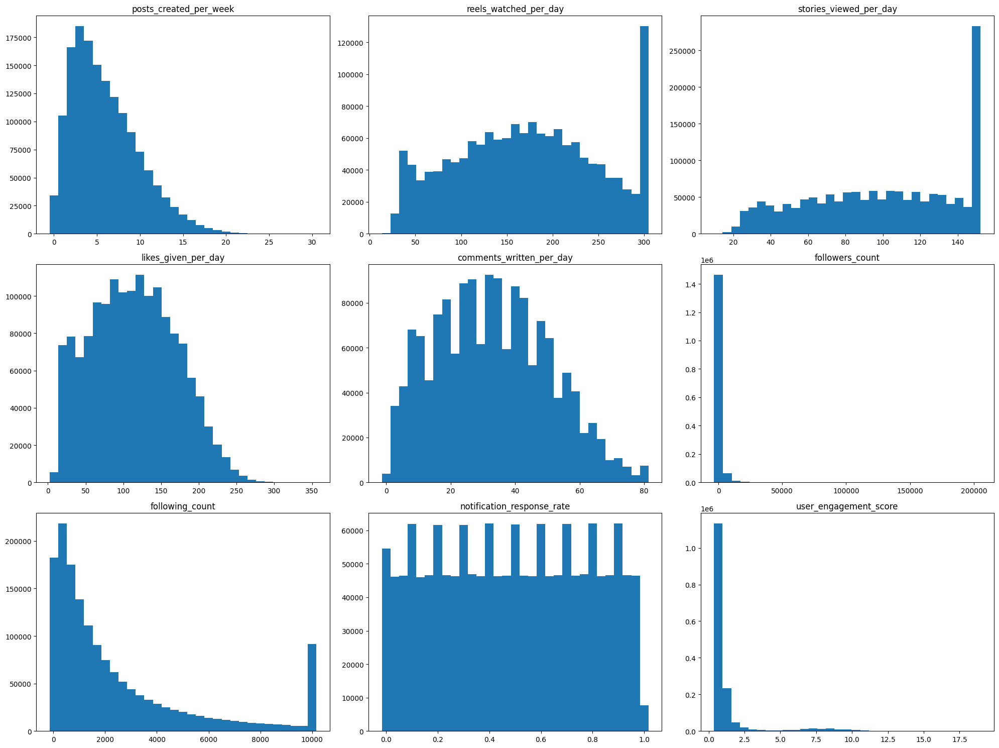

In [0]:
import math
import matplotlib.pyplot as plt

cols = [
    'posts_created_per_week',
    'reels_watched_per_day',
    'stories_viewed_per_day',
    'likes_given_per_day',
    'comments_written_per_day',
    'followers_count',
    'following_count',
    'notification_response_rate',
    'user_engagement_score'
]

n = len(cols)
cols_per_row = 3
rows = math.ceil(n / cols_per_row)

fig, axes = plt.subplots(rows, cols_per_row, figsize=(20, 5 * rows))
axes = axes.flatten()

for i, col in enumerate(cols):
    hist_pdf, min_val, bin_width = compute_histogram(df, col, bins=30)

    # Convert bin index → actual values
    x = min_val + hist_pdf["bin"] * bin_width
    y = hist_pdf["count"]

    axes[i].bar(x, y, width=bin_width)
    axes[i].set_title(col)

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
display(fig)
plt.close(fig)

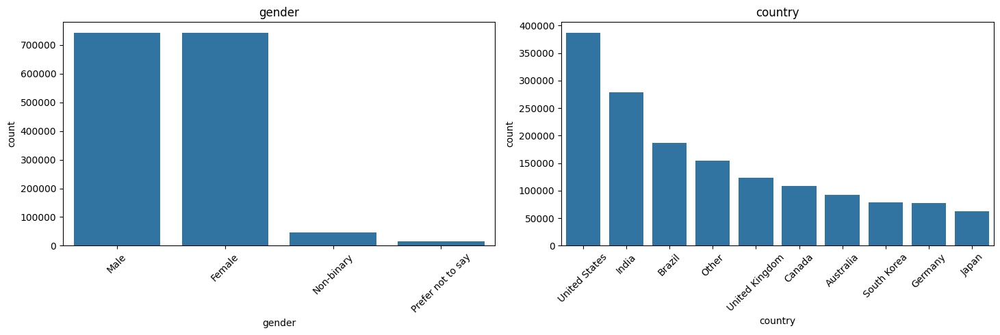

In [0]:
# Categorical plots using FULL dataset (Spark)
import math
import matplotlib.pyplot as plt
import seaborn as sns

cat_cols = [
    'gender',
    'country',
]

n = len(cat_cols)
cols_per_row = 3
rows = math.ceil(n / cols_per_row)

fig, axes = plt.subplots(rows, cols_per_row, figsize=(22, 5 * rows))
axes = axes.flatten()

for i, col in enumerate(cat_cols):

    # Step 1: Aggregate FULL dataset in Spark
    agg_df = (
        df.groupBy(col)
        .count()
        .orderBy("count", ascending=False)
    )

    # Step 2: Convert small result to Pandas
    pdf_small = agg_df.toPandas()

    # Step 3: Plot using seaborn
    sns.barplot(
        data=pdf_small,
        x=col,
        y="count",
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()
plt.close(fig)

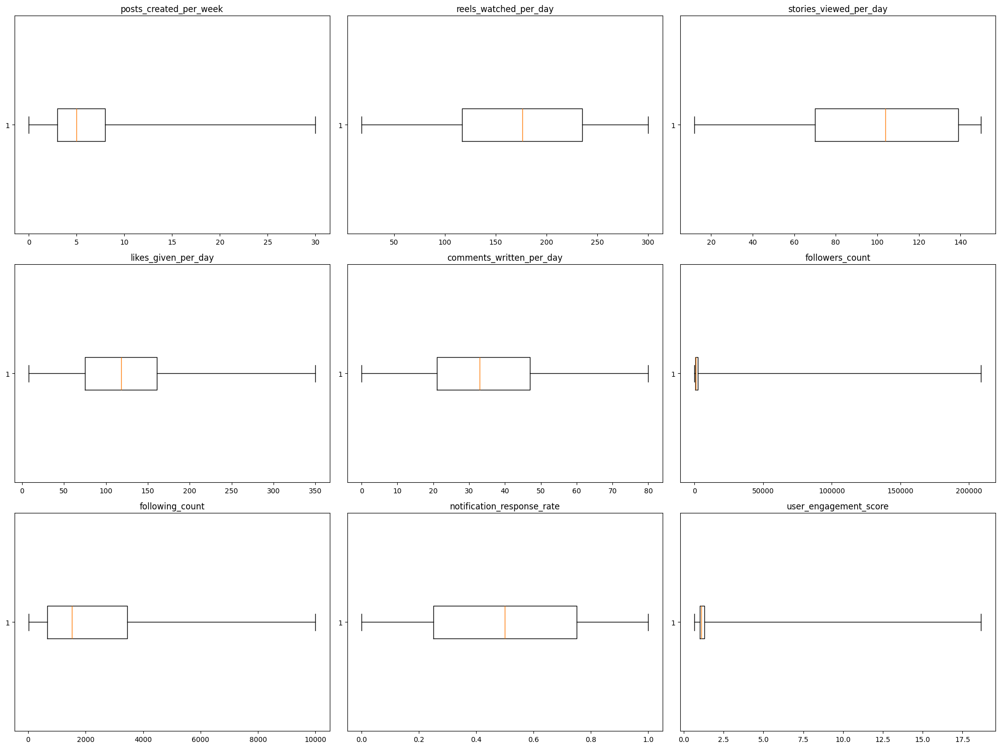

In [0]:
# Boxplots using FULL dataset 

import math
import matplotlib.pyplot as plt
import numpy as np

Num_cols = [
    'posts_created_per_week',
    'reels_watched_per_day',
    'stories_viewed_per_day',
    'likes_given_per_day',
    'comments_written_per_day',
    'followers_count',
    'following_count',
    'notification_response_rate',
    'user_engagement_score'
]

cols = Num_cols
n = len(cols)

cols_per_row = 3
rows = math.ceil(n / cols_per_row)

fig, axes = plt.subplots(rows, cols_per_row, figsize=(20, 5 * rows))
axes = axes.flatten()

for i, col in enumerate(cols):

    # ------------------------------------------
    # Step 1: Compute boxplot stats from FULL data
    # ------------------------------------------
    quantiles = df.approxQuantile(
        col,
        [0.0, 0.25, 0.5, 0.75, 1.0],  # min, Q1, median, Q3, max
        0.001
    )

    min_val, q1, median, q3, max_val = quantiles

    # ------------------------------------------
    # Step 2: Build boxplot manually
    # ------------------------------------------
    stats = [{
        'med': median,
        'q1': q1,
        'q3': q3,
        'whislo': min_val,  # lower whisker
        'whishi': max_val,  # upper whisker
        'fliers': []        # skip outliers (too expensive at scale)
    }]

    axes[i].bxp(stats, vert=False)
    axes[i].set_title(col)

# ------------------------------------------
# Remove empty subplots
# ------------------------------------------
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
display(fig)
plt.close(fig)

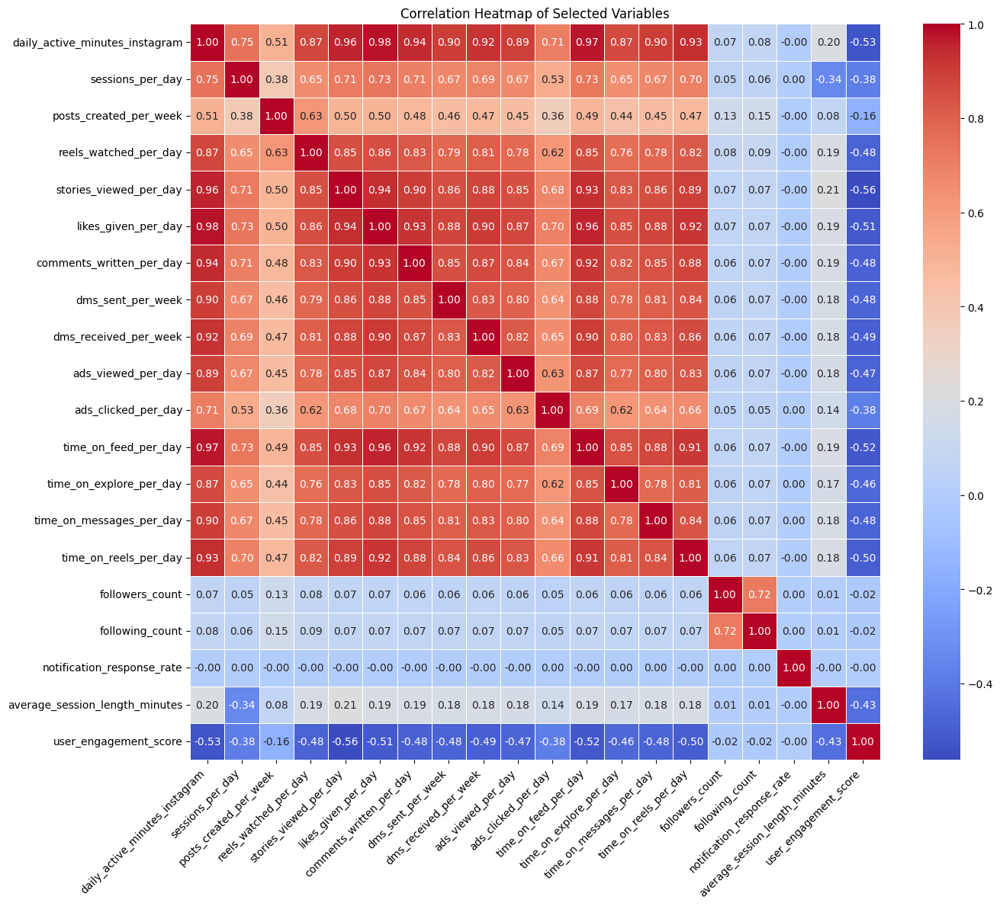

In [0]:
# Heatmap for correlation among numerical columns
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from itertools import combinations

important_cols = [
    'daily_active_minutes_instagram',
    'sessions_per_day',
    'posts_created_per_week',
    'reels_watched_per_day',
    'stories_viewed_per_day',
    'likes_given_per_day',
    'comments_written_per_day',
    'dms_sent_per_week',
    'dms_received_per_week',
    'ads_viewed_per_day',
    'ads_clicked_per_day',
    'time_on_feed_per_day',
    'time_on_explore_per_day',
    'time_on_messages_per_day',
    'time_on_reels_per_day',
    'followers_count',
    'following_count',
    'notification_response_rate',
    'average_session_length_minutes',
    'user_engagement_score'
]

# Compute correlation matrix using Spark
corr_dict = {}
for col1, col2 in combinations(important_cols, 2):
    corr_dict[(col1, col2)] = df.stat.corr(col1, col2)

# Build symmetric correlation matrix
corr_matrix = pd.DataFrame(index=important_cols, columns=important_cols, dtype=float)
for i, col1 in enumerate(important_cols):
    for j, col2 in enumerate(important_cols):
        if i == j:
            corr_matrix.loc[col1, col2] = 1.0
        elif i < j:
            corr_matrix.loc[col1, col2] = corr_dict.get((col1, col2), corr_dict.get((col2, col1)))
        else:
            corr_matrix.loc[col1, col2] = corr_dict.get((col2, col1), corr_dict.get((col1, col2)))

# Plot heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix.astype(float),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Selected Variables")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_multiple_with_corr(pairs, df):

    n = len(pairs)
    fig, axes = plt.subplots(1, n, figsize=(6*n, 4))

    # Ensure axes is always iterable
    if n == 1:
        axes = [axes]

    for i, (x_col, y_col) in enumerate(pairs):

        try:
            # correlation (Spark)
            corr = df.stat.corr(x_col, y_col)

            # sample data
            sample_pdf = (
                df.select(x_col, y_col)
                .dropna()
                .sample(False, 0.05, seed=42)
                .toPandas()
            )

            # plot
            sns.scatterplot(
                data=sample_pdf,
                x=x_col,
                y=y_col,
                alpha=0.4,
                ax=axes[i]
            )

            axes[i].set_title(f'{x_col} vs {y_col}\nCorr: {corr:.2f}')

        except Exception as e:
            axes[i].set_title(f"Error: {x_col} vs {y_col}")
            print(f"Error in plot {i}: ", e)

    plt.tight_layout()
    plt.show()

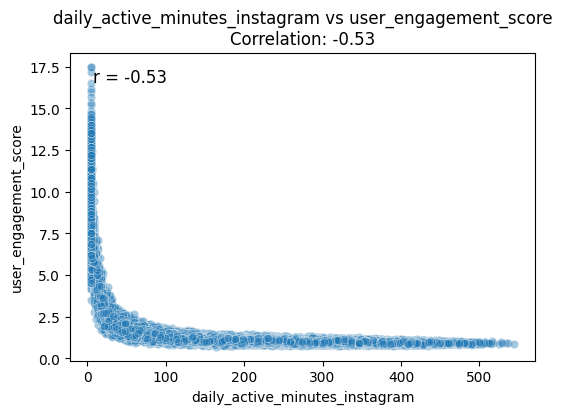

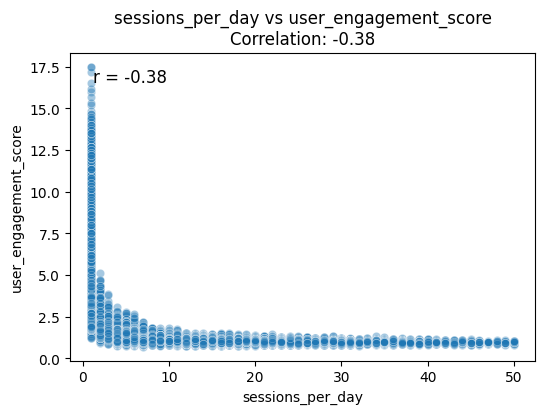

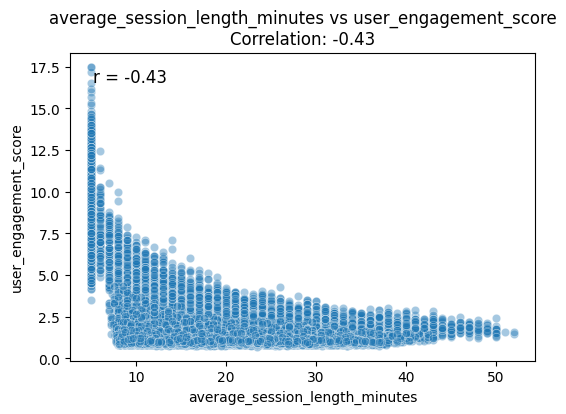

In [0]:
# BIVARIATE ANALYSIS#
pdf = df.toPandas()
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plots

# a) Core engagement relationships (relationships between key user activity behaviors and engagement outcomes)
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plots with correlation (FULL DATA SAFE)

def plot_with_corr(x_col, y_col, df):

    # correlation computed on full dataset (no Pandas needed)
    corr = df.stat.corr(x_col, y_col)

    # small sample only for visualization
    sample_pdf = (
        df.select(x_col, y_col)
        .sample(False, 0.05, seed=42)
        .toPandas()
    )

    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=sample_pdf, x=x_col, y=y_col, alpha=0.4)

    plt.title(f'{x_col} vs {y_col}\nCorrelation: {corr:.2f}')

    plt.text(
        0.05, 0.95,
        f'r = {corr:.2f}',
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment='top'
    )

    plt.show()


plot_with_corr('daily_active_minutes_instagram', 'user_engagement_score', df)
plot_with_corr('sessions_per_day', 'user_engagement_score', df)
plot_with_corr('average_session_length_minutes', 'user_engagement_score', df)

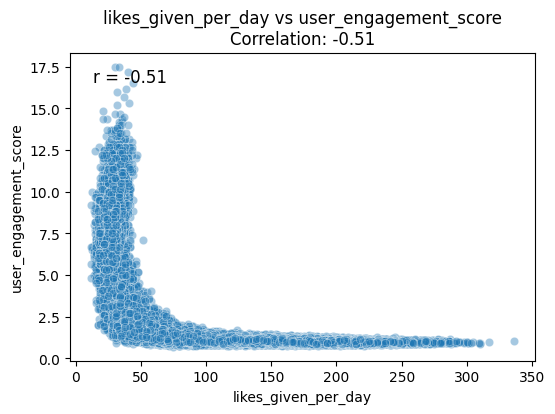

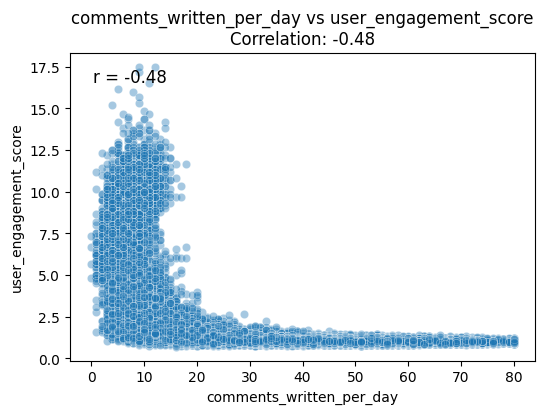

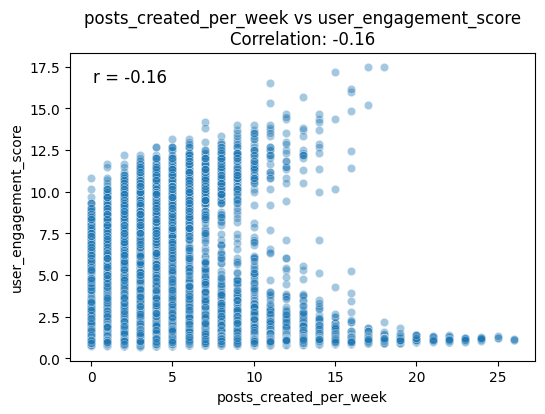

In [0]:
# b) Content interaction vs engagement
import seaborn as sns
import matplotlib.pyplot as plt

def plot_with_corr(x_col, y_col, df):

    # full dataset correlation (Spark)
    corr = df.stat.corr(x_col, y_col)

    # sample only for visualization
    sample_pdf = (
        df.select(x_col, y_col)
        .sample(False, 0.05, seed=42)
        .toPandas()
    )

    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=sample_pdf, x=x_col, y=y_col, alpha=0.4)

    plt.title(f'{x_col} vs {y_col}\nCorrelation: {corr:.2f}')

    plt.text(
        0.05, 0.95,
        f'r = {corr:.2f}',
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment='top'
    )

    plt.show()


plot_with_corr('likes_given_per_day', 'user_engagement_score', df)
plot_with_corr('comments_written_per_day', 'user_engagement_score', df)
plot_with_corr('posts_created_per_week', 'user_engagement_score', df)

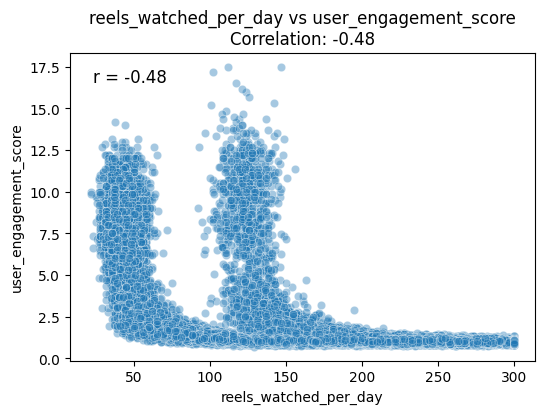

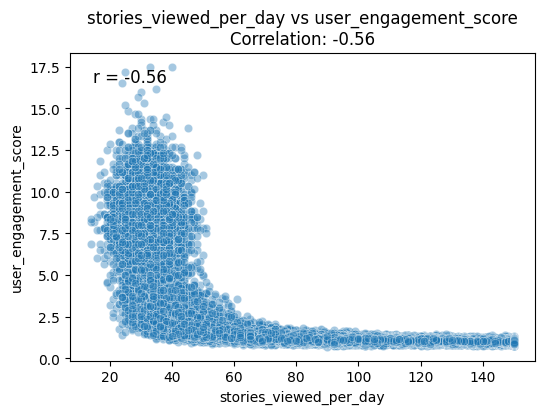

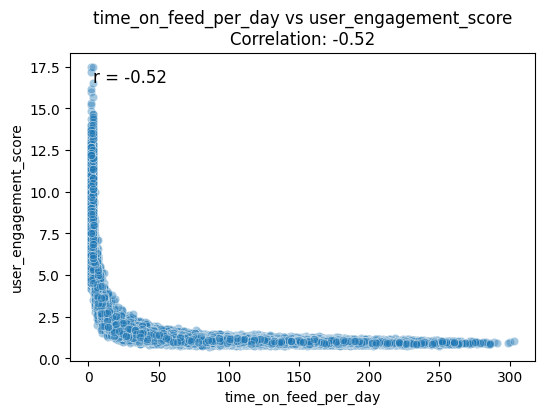

In [0]:
# # Consumption behavior vs engagement (FULL DATA)
import seaborn as sns
import matplotlib.pyplot as plt


def plot_with_corr(x_col, y_col, df):

    # correlation computed on FULL dataset (Spark)
    corr = df.stat.corr(x_col, y_col)

    # small sample only for visualization
    sample_pdf = (
        df.select(x_col, y_col)
        .sample(False, 0.05, seed=42)
        .toPandas()
    )

    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=sample_pdf, x=x_col, y=y_col, alpha=0.4)

    plt.title(f'{x_col} vs {y_col}\nCorrelation: {corr:.2f}')

    plt.text(
        0.05, 0.95,
        f'r = {corr:.2f}',
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment='top'
    )

    plt.show()


# Plots
plot_with_corr('reels_watched_per_day', 'user_engagement_score', df)
plot_with_corr('stories_viewed_per_day', 'user_engagement_score', df)
plot_with_corr('time_on_feed_per_day', 'user_engagement_score', df)


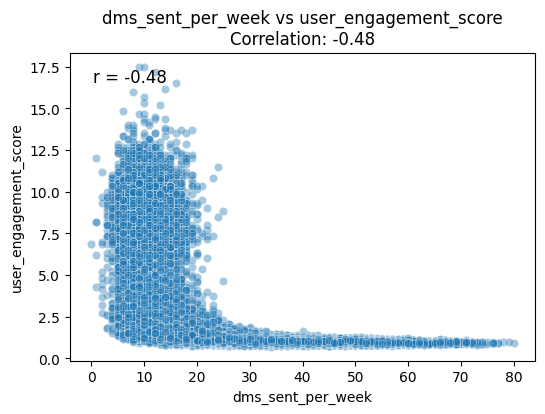

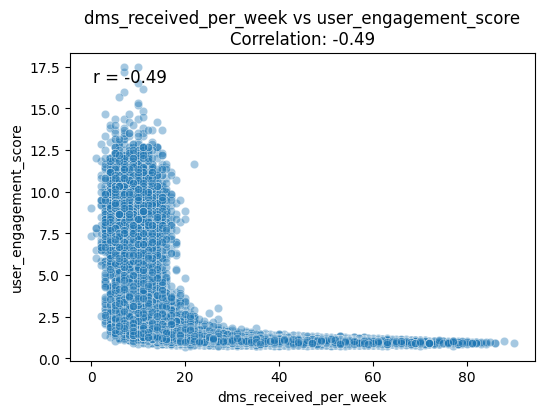

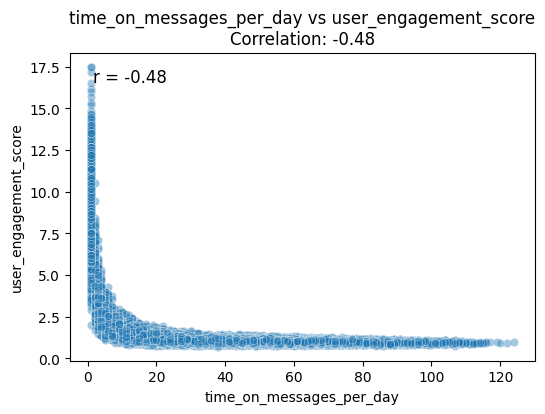

In [0]:
# d) Messaging behavior vs engagement (FULL DATA)
import seaborn as sns
import matplotlib.pyplot as plt

def plot_with_corr(x_col, y_col, df):

    # correlation computed on FULL dataset (Spark)
    corr = df.stat.corr(x_col, y_col)

    # sample only for visualization (scatter plot)
    sample_pdf = (
        df.select(x_col, y_col)
        .sample(False, 0.05, seed=42)
        .toPandas()
    )

    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=sample_pdf, x=x_col, y=y_col, alpha=0.4)

    plt.title(f'{x_col} vs {y_col}\nCorrelation: {corr:.2f}')

    plt.text(
        0.05, 0.95,
        f'r = {corr:.2f}',
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment='top'
    )

    plt.show()


# Plots
plot_with_corr('dms_sent_per_week', 'user_engagement_score', df)
plot_with_corr('dms_received_per_week', 'user_engagement_score', df)
plot_with_corr('time_on_messages_per_day', 'user_engagement_score', df)

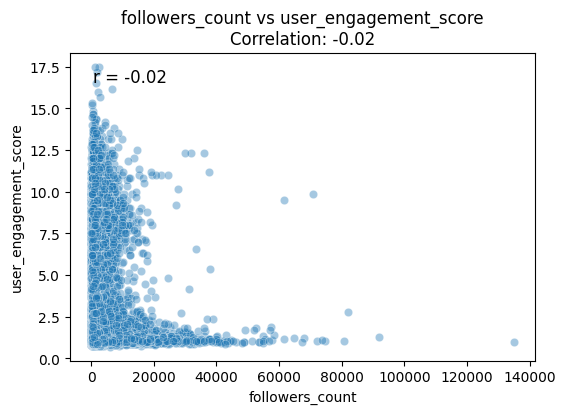

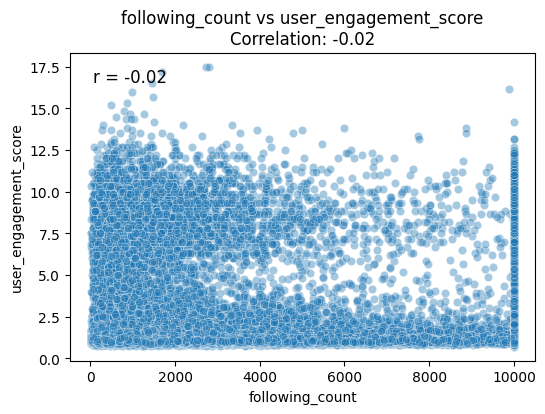

In [0]:
# e) Audience size vs engagement (FULL DATA SAFE)
import seaborn as sns
import matplotlib.pyplot as plt
def plot_with_corr(x_col, y_col, df):

    # correlation using FULL dataset (Spark)
    corr = df.stat.corr(x_col, y_col)

    # sample only for visualization
    sample_pdf = (
        df.select(x_col, y_col)
        .sample(False, 0.05, seed=42)
        .toPandas()
    )

    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=sample_pdf, x=x_col, y=y_col, alpha=0.4)

    plt.title(f'{x_col} vs {y_col}\nCorrelation: {corr:.2f}')

    plt.text(
        0.05, 0.95,
        f'r = {corr:.2f}',
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment='top'
    )

    plt.show()


# Plots
plot_with_corr('followers_count', 'user_engagement_score', df)
plot_with_corr('following_count', 'user_engagement_score', df)

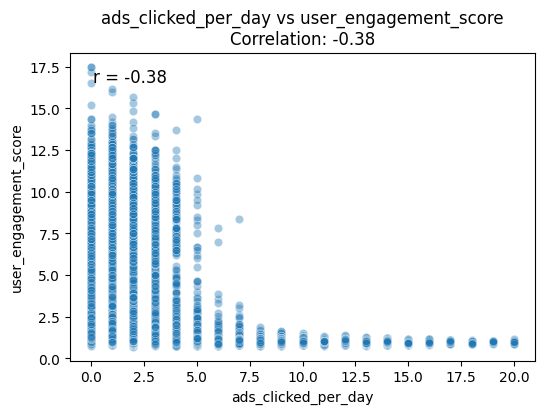

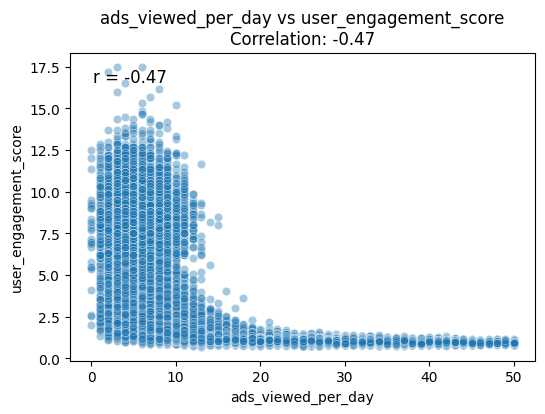

In [0]:
# Ads behavior vs engagement (FULL DATA SAFE)
import seaborn as sns
import matplotlib.pyplot as plt

def plot_with_corr(x_col, y_col, df):

    # correlation using FULL dataset (Spark)
    corr = df.stat.corr(x_col, y_col)

    # small sample for scatter plot only
    sample_pdf = (
        df.select(x_col, y_col)
        .sample(False, 0.05, seed=42)
        .toPandas()
    )

    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=sample_pdf, x=x_col, y=y_col, alpha=0.4)

    plt.title(f'{x_col} vs {y_col}\nCorrelation: {corr:.2f}')

    plt.text(
        0.05, 0.95,
        f'r = {corr:.2f}',
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment='top'
    )

    plt.show()


# Plots
plot_with_corr('ads_clicked_per_day', 'user_engagement_score', df)
plot_with_corr('ads_viewed_per_day', 'user_engagement_score', df)

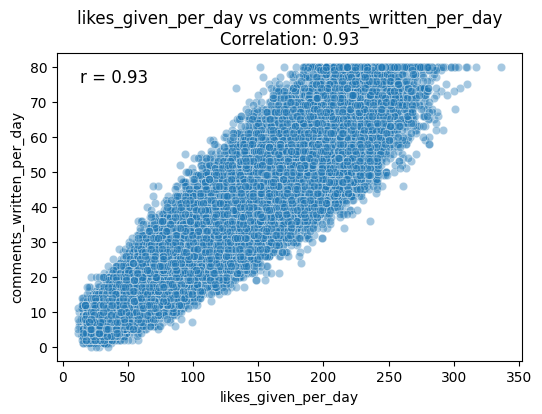

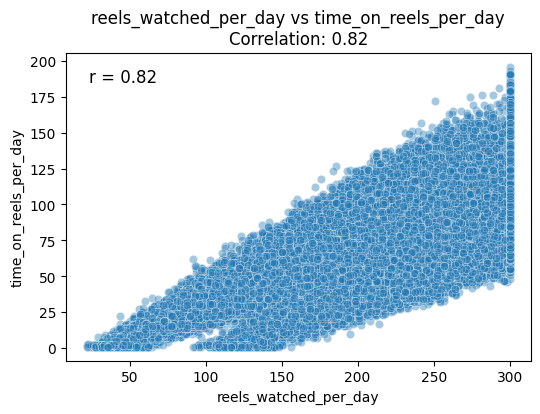

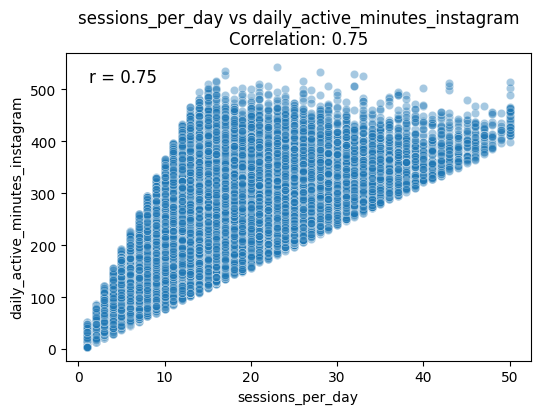

In [0]:
# Cross-feature scatter plots (for bot detection)
import seaborn as sns
import matplotlib.pyplot as plt


def plot_with_corr(x_col, y_col, df):

    # correlation computed on FULL dataset (Spark)
    corr = df.stat.corr(x_col, y_col)

    # small sample only for visualization
    sample_pdf = (
        df.select(x_col, y_col)
        .sample(False, 0.05, seed=42)
        .toPandas()
    )

    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=sample_pdf, x=x_col, y=y_col, alpha=0.4)

    plt.title(f'{x_col} vs {y_col}\nCorrelation: {corr:.2f}')

    plt.text(
        0.05, 0.95,
        f'r = {corr:.2f}',
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment='top'
    )

    plt.show()


# Plots
plot_with_corr('likes_given_per_day', 'comments_written_per_day', df)
plot_with_corr('reels_watched_per_day', 'time_on_reels_per_day', df)
plot_with_corr('sessions_per_day', 'daily_active_minutes_instagram', df)
  

In [0]:
# Selecting columns for feature selection
selected_columns = [
    "daily_active_minutes_instagram",
    "sessions_per_day",
    "posts_created_per_week",
    "time_on_feed_per_day",
    "time_on_explore_per_day",
    "time_on_messages_per_day",
    "time_on_reels_per_day",
    "average_session_length_minutes",
    "reels_watched_per_day",
    "stories_viewed_per_day",
    "likes_given_per_day",
    "comments_written_per_day",
    "dms_sent_per_week",
    "dms_received_per_week",
    "ads_viewed_per_day",
    "ads_clicked_per_day",
    "user_engagement_score",
    "followers_count",
    "following_count",
    "account_creation_year",
    "last_login_date",
    "notification_response_rate"
]

df_filtered = df.select(selected_columns)

In [0]:
# Saving the new Dataset as table
df_filtered.write.mode("overwrite").saveAsTable("instagram_filtered_dataset")

In [0]:
# Checking the no of columns and row of the filtered dataset
filtered_df = spark.table("instagram_filtered_dataset")
print("Number of rows:", filtered_df.count())
print("Number of columns:", len(filtered_df.columns))

Number of rows: 1547896
Number of columns: 22


In [0]:
%sql
SELECT * FROM instagram_filtered_dataset;

daily_active_minutes_instagram,sessions_per_day,posts_created_per_week,time_on_feed_per_day,time_on_explore_per_day,time_on_messages_per_day,time_on_reels_per_day,average_session_length_minutes,reels_watched_per_day,stories_viewed_per_day,likes_given_per_day,comments_written_per_day,dms_sent_per_week,dms_received_per_week,ads_viewed_per_day,ads_clicked_per_day,user_engagement_score,followers_count,following_count,account_creation_year,last_login_date,notification_response_rate
5.0,1,3,2,1,1,2,5.0,42,28,28,5,12,12,4,1,7.83,374,647,2015,2025-11-02,0.34
74.0,5,3,31,19,16,19,14.8,78,54,68,15,18,10,11,1,1.43,2585,3511,2018,2025-03-22,0.56
5.0,1,7,3,1,1,1,5.0,29,26,25,6,12,13,4,0,9.67,3414,6761,2011,2025-08-10,0.73
233.0,9,5,108,64,52,64,25.9,241,109,132,36,31,32,33,3,0.94,617,1193,2019,2025-03-31,0.73
184.0,14,5,78,55,22,55,13.1,146,113,103,36,29,37,20,5,1.03,1157,1072,2017,2025-03-19,0.65
49.0,3,3,29,6,12,13,16.3,150,41,55,9,13,13,16,3,1.64,259,534,2013,2025-02-09,0.13
125.0,4,7,64,21,26,44,31.2,112,79,80,20,18,34,14,5,1.12,4373,8085,2012,2025-05-06,0.79
282.0,14,5,167,49,50,87,20.1,227,144,158,50,26,37,20,9,0.96,190,77,2014,2025-11-17,0.22
128.0,10,2,64,38,31,50,12.8,118,90,90,16,20,18,23,2,0.99,904,1129,2011,2025-05-10,0.98
196.0,13,5,115,34,27,58,15.1,176,93,131,27,22,30,24,1,1.02,170,247,2011,2025-09-13,0.6


In [0]:
df_filtered = spark.table("instagram_filtered_dataset")

In [0]:
# Feature Engineering
# A Engagement Rate
from pyspark.sql.functions import col, lit
df_filtered = df_filtered.withColumn(
    "engagement_rate",
    (col("likes_given_per_day") + col("comments_written_per_day")) /
    (col("followers_count") + 1)
)

# B: Follow Ratio
df_filtered = df_filtered.withColumn(
    "follow_ratio",
    col("followers_count") / (col("following_count") + 1)
)

# C: DM Ratio
df_filtered = df_filtered.withColumn(
    "dm_ratio",
    col("dms_sent_per_week") / (col("dms_received_per_week") + 1)
)

# D: Activity Score
df_filtered = df_filtered.withColumn(
    "activity_score",
    col("sessions_per_day") +
    col("posts_created_per_week") +
    col("likes_given_per_day")
)
# E: Account Age
df_filtered = df_filtered.withColumn(
    "account_age",
    lit(2026) - col("account_creation_year")
)

# F: Creating Last Login to days
from pyspark.sql.functions import col, current_date, to_date, datediff

df_filtered = df_filtered.withColumn(
    "last_login_days",
    datediff(current_date(), to_date(col("last_login_date")))
)

In [0]:
print("Number of rows:", df_filtered.count())
print("Number of columns:", len(df_filtered.columns))

Number of rows: 1547896
Number of columns: 28


In [0]:
# Score for label
from pyspark.sql.functions import col, when

df_filtered = df_filtered.withColumn(
    "score",

    # Over-activity
    when(col("sessions_per_day") > 12, 1).otherwise(0) +
    when(col("daily_active_minutes_instagram") > 180, 1).otherwise(0) +

    # Low quality engagement
    when(col("average_session_length_minutes") < 3, 1).otherwise(0) +

    # Social imbalance
    when((col("follow_ratio") > 4) | (col("follow_ratio") < 0.2), 1).otherwise(0) +
    when((col("dm_ratio") > 5) | (col("dm_ratio") < 0.1), 1).otherwise(0) +
    when(col("engagement_rate") > 0.6, 1).otherwise(0) +

    # Content & ads abnormality
    when(col("reels_watched_per_day") > 80, 1).otherwise(0) +
    when(col("stories_viewed_per_day") > 120, 1).otherwise(0) +
    when(col("ads_clicked_per_day") > 10, 1).otherwise(0) +
    when(col("ads_viewed_per_day") > 80, 1).otherwise(0)
)

In [0]:
# Converting score to Label
from pyspark.sql.functions import when, col

df_filtered = df_filtered.withColumn(
    "label",
    when(
        (col("activity_score") > 100) & 
        (col("engagement_rate") < 0.05),
        1
    ).otherwise(0)
)

In [0]:
print("Number of rows:", df_filtered.count())
print("Number of columns:", len(df_filtered.columns))

Number of rows: 1547896
Number of columns: 30


In [0]:
df_filtered.groupBy("label").count().show()

+-----+-------+
|label|  count|
+-----+-------+
|    0|1379742|
|    1| 168154|
+-----+-------+



In [0]:
df_filtered.columns

['daily_active_minutes_instagram',
 'sessions_per_day',
 'posts_created_per_week',
 'time_on_feed_per_day',
 'time_on_explore_per_day',
 'time_on_messages_per_day',
 'time_on_reels_per_day',
 'average_session_length_minutes',
 'reels_watched_per_day',
 'stories_viewed_per_day',
 'likes_given_per_day',
 'comments_written_per_day',
 'dms_sent_per_week',
 'dms_received_per_week',
 'ads_viewed_per_day',
 'ads_clicked_per_day',
 'user_engagement_score',
 'followers_count',
 'following_count',
 'account_creation_year',
 'last_login_date',
 'notification_response_rate',
 'engagement_rate',
 'follow_ratio',
 'dm_ratio',
 'activity_score',
 'account_age',
 'last_login_days',
 'score',
 'label']

In [0]:
# Limiting the dataset

from pyspark.sql.functions import col

df_clean = df_filtered.drop(
    "time_on_feed_per_day",
    "time_on_explore_per_day",
    "time_on_messages_per_day",
    "time_on_reels_per_day",
    "user_engagement_score",
    "account_creation_year",
    "dms_sent_per_week",
    "dms_received_per_week",
    "last_login_date"
)

In [0]:
df_clean.columns

['daily_active_minutes_instagram',
 'sessions_per_day',
 'posts_created_per_week',
 'average_session_length_minutes',
 'reels_watched_per_day',
 'stories_viewed_per_day',
 'likes_given_per_day',
 'comments_written_per_day',
 'ads_viewed_per_day',
 'ads_clicked_per_day',
 'followers_count',
 'following_count',
 'notification_response_rate',
 'engagement_rate',
 'follow_ratio',
 'dm_ratio',
 'activity_score',
 'account_age',
 'last_login_days',
 'score',
 'label']

In [0]:
print("Number of rows:", df_clean.count())
print("Number of columns:", len(df_clean.columns))

Number of rows: 1547896
Number of columns: 21


In [0]:
df_clean.groupBy("label").count().show()

+-----+-------+
|label|  count|
+-----+-------+
|    0|1379742|
|    1| 168154|
+-----+-------+



In [0]:
from pyspark.ml.feature import VectorAssembler

leakage_features = [
    "activity_score",
    "engagement_rate",
    "dm_ratio",
    "score",
    "percentile"
]

feature_cols = [
    col for col in df_clean.columns
    if col not in ["label"] + leakage_features
]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

df_model = assembler.transform(df_clean)


In [0]:
# Logistic regression
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, RegressionEvaluator

# 1. Split data
train_data, test_data = df_model.randomSplit([0.7, 0.3], seed=42)

# 2. Model
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100
)

# 3. Train
lr_model = lr.fit(train_data)

# 4. Predict
lr_predictions = lr_model.transform(test_data)

# 5. Evaluators
multi_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
reg_eval = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")

accuracy = multi_eval.setMetricName("accuracy").evaluate(lr_predictions)
f1 = multi_eval.setMetricName("f1").evaluate(lr_predictions)
precision = multi_eval.setMetricName("weightedPrecision").evaluate(lr_predictions)
recall = multi_eval.setMetricName("weightedRecall").evaluate(lr_predictions)
rmse = reg_eval.evaluate(lr_predictions)

# 6. Print Results
print("===== Logistic Regression =====")
print(f"Accuracy:  {accuracy:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"RMSE:      {rmse:.4f}")

# 7. Confusion Matrix-style Output
lr_predictions.groupBy("label", "prediction").count().show()


===== Logistic Regression =====
Accuracy:  0.9333
F1 Score:  0.9295
Precision: 0.9283
Recall:    0.9333
RMSE:      0.2582
+-----+----------+------+
|label|prediction| count|
+-----+----------+------+
|    0|       0.0|403843|
|    1|       0.0| 21194|
|    1|       1.0| 29003|
|    0|       1.0|  9728|
+-----+----------+------+



In [0]:
# Gradient Boost Model
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, RegressionEvaluator

# 1. Split data
train_data, test_data = df_model.randomSplit([0.7, 0.3], seed=42)

# 2. Model
gbt = GBTClassifier(
    featuresCol="features",
    labelCol="label",
    maxIter=50,
    maxDepth=10,
    seed=42
)

# 3. Training
gbt_model = gbt.fit(train_data)

# 4. Prediction
gbt_predictions = gbt_model.transform(test_data)

# 5. Evaluation
multi_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
reg_eval = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")

accuracy = multi_eval.setMetricName("accuracy").evaluate(gbt_predictions)
f1 = multi_eval.setMetricName("f1").evaluate(gbt_predictions)
precision = multi_eval.setMetricName("weightedPrecision").evaluate(gbt_predictions)
recall = multi_eval.setMetricName("weightedRecall").evaluate(gbt_predictions)
rmse = reg_eval.evaluate(gbt_predictions)

print("===== Gradient Boosted Trees =====")
print(f"Accuracy:  {accuracy:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"RMSE:      {rmse:.4f}")

gbt_predictions.groupBy("label", "prediction").count().show()

===== Gradient Boosted Trees =====
Accuracy:  0.9930
F1 Score:  0.9930
Precision: 0.9930
Recall:    0.9930
RMSE:      0.0839
+-----+----------+------+
|label|prediction| count|
+-----+----------+------+
|    0|       0.0|411959|
|    1|       0.0|  1655|
|    1|       1.0| 48542|
|    0|       1.0|  1612|
+-----+----------+------+



In [0]:
# Random Forest Model 
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, RegressionEvaluator

# 1. Split data
train_data, test_data = df_model.randomSplit([0.7, 0.3], seed=42)

# 2. Model
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=10,
    seed=42
)

# 3. Training
rf_model = rf.fit(train_data)

# 4. Prediction
rf_predictions = rf_model.transform(test_data)

# 5. Evaluation
multi_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
reg_eval = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")

accuracy = multi_eval.setMetricName("accuracy").evaluate(rf_predictions)
f1 = multi_eval.setMetricName("f1").evaluate(rf_predictions)
precision = multi_eval.setMetricName("weightedPrecision").evaluate(rf_predictions)
recall = multi_eval.setMetricName("weightedRecall").evaluate(rf_predictions)
rmse = reg_eval.evaluate(rf_predictions)

print("===== Random Forest =====")
print(f"Accuracy:  {accuracy:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"RMSE:      {rmse:.4f}")

rf_predictions.groupBy("label", "prediction").count().show()

===== Random Forest =====
Accuracy:  0.9899
F1 Score:  0.9899
Precision: 0.9899
Recall:    0.9899
RMSE:      0.1005
+-----+----------+------+
|label|prediction| count|
+-----+----------+------+
|    0|       0.0|411480|
|    1|       0.0|  2590|
|    1|       1.0| 47607|
|    0|       1.0|  2091|
+-----+----------+------+



In [0]:
import os

os.environ["SPARKML_TEMP_DFS_PATH"] = "/Volumes/my_catalog/my_schema/my_volume/spark_temp/"

In [0]:
# Cross Validation and Hyperparameter Tuning Set up
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

# Evaluator (used in CV)
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

In [0]:
# CV and Hyperparameter Tuning for Logistic Regression
from pyspark.ml.classification import LogisticRegression

# Split data first
train_data, test_data = df_model.randomSplit([0.7, 0.3], seed=42)

lr = LogisticRegression(labelCol="label", featuresCol="features")

# Hyperparameter grid
lr_paramGrid = (ParamGridBuilder()
    .addGrid(lr.regParam, [0.01, 0.1, 1.0])
    .addGrid(lr.maxIter, [50, 100])
    .build()
)

# Cross Validator
lr_cv = CrossValidator(
    estimator=lr,
    estimatorParamMaps=lr_paramGrid,
    evaluator=evaluator,
    numFolds=5,
    seed=42
)

# Train CV model on training data
lr_cv_model = lr_cv.fit(train_data)

# Best model predictions on test data
lr_predictions = lr_cv_model.transform(test_data)

In [0]:
# Evaluation of CV and hyperparameter tuning of Logistic Regression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, RegressionEvaluator

multi_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
reg_eval = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")

accuracy = multi_eval.setMetricName("accuracy").evaluate(lr_predictions)
f1 = multi_eval.setMetricName("f1").evaluate(lr_predictions)
precision = multi_eval.setMetricName("weightedPrecision").evaluate(lr_predictions)
recall = multi_eval.setMetricName("weightedRecall").evaluate(lr_predictions)
rmse = reg_eval.evaluate(lr_predictions)

print("===== Logistic Regression (CV Tuned) =====")
print(f"Accuracy:  {accuracy:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"RMSE:      {rmse:.4f}")

lr_predictions.groupBy("label", "prediction").count().show()

===== Logistic Regression (CV Tuned) =====
Accuracy:  0.9316
F1 Score:  0.9259
Precision: 0.9256
Recall:    0.9316
RMSE:      0.2615
+-----+----------+------+
|label|prediction| count|
+-----+----------+------+
|    0|       0.0|405560|
|    1|       0.0| 23714|
|    1|       1.0| 26483|
|    0|       1.0|  8011|
+-----+----------+------+



In [0]:
from pyspark.ml.classification import GBTClassifier

gbt = GBTClassifier(labelCol="label", featuresCol="features")

gbt_paramGrid = (ParamGridBuilder()
    .addGrid(gbt.maxIter, [20, 50])
    .addGrid(gbt.maxDepth, [5, 10])
    .build()
)

gbt_cv = CrossValidator(
    estimator=gbt,
    estimatorParamMaps=gbt_paramGrid,
    evaluator=evaluator,
    numFolds=5,
    seed=42
)

gbt_cv_model = gbt_cv.fit(train_data)
gbt_predictions = gbt_cv_model.transform(test_data)

In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, RegressionEvaluator

# Evaluators
multi_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
reg_eval = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")

accuracy = multi_eval.setMetricName("accuracy").evaluate(gbt_predictions)
f1 = multi_eval.setMetricName("f1").evaluate(gbt_predictions)
precision = multi_eval.setMetricName("weightedPrecision").evaluate(gbt_predictions)
recall = multi_eval.setMetricName("weightedRecall").evaluate(gbt_predictions)
rmse = reg_eval.evaluate(gbt_predictions)

print("===== Gradient Boosted Trees (CV Tuned) =====")
print(f"Accuracy:  {accuracy:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"RMSE:      {rmse:.4f}")

gbt_predictions.groupBy("label", "prediction").count().show()

===== Gradient Boosted Trees (CV Tuned) =====
Accuracy:  0.9928
F1 Score:  0.9928
Precision: 0.9928
Recall:    0.9928
RMSE:      0.0849
+-----+----------+------+
|label|prediction| count|
+-----+----------+------+
|    0|       0.0|411915|
|    1|       0.0|  1684|
|    1|       1.0| 48513|
|    0|       1.0|  1656|
+-----+----------+------+



In [0]:
# Random Forest CV and Hypertuing Test
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

rf = RandomForestClassifier(labelCol="label", featuresCol="features")

paramGrid = ParamGridBuilder() \
    .addGrid(rf.numTrees, [50, 100]) \
    .addGrid(rf.maxDepth, [5, 10]) \
    .build()

evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

cv = CrossValidator(
    estimator=rf,
    estimatorParamMaps=paramGrid,
    evaluator=evaluator,
    numFolds=5
)

cvModel = cv.fit(train_data)

rf_predictions = cvModel.transform(test_data)

In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
import matplotlib.pyplot as plt


# 1. EVALUATION METRICS
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction"
)

accuracy = evaluator.setMetricName("accuracy").evaluate(rf_predictions)
f1 = evaluator.setMetricName("f1").evaluate(rf_predictions)
precision = evaluator.setMetricName("weightedPrecision").evaluate(rf_predictions)
recall = evaluator.setMetricName("weightedRecall").evaluate(rf_predictions)

print("===== Random Forest CV Results =====")
print(f"Accuracy:  {accuracy:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")

===== Random Forest CV Results =====
Accuracy:  0.9899
F1 Score:  0.9899
Precision: 0.9899
Recall:    0.9899


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
import pandas as pd
import matplotlib.pyplot as plt


# Evaluation function

def evaluate_model(predictions, name):
    evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

    accuracy = evaluator.setMetricName("accuracy").evaluate(predictions)
    f1 = evaluator.setMetricName("f1").evaluate(predictions)
    precision = evaluator.setMetricName("weightedPrecision").evaluate(predictions)
    recall = evaluator.setMetricName("weightedRecall").evaluate(predictions)

    return {
        "Model": name,
        "Accuracy": accuracy,
        "F1": f1,
        "Precision": precision,
        "Recall": recall
    }


# Collect results

results = [
    evaluate_model(lr_predictions, "Logistic Regression"),
    evaluate_model(rf_predictions, "Random Forest"),
    evaluate_model(gbt_predictions, "Gradient Boosting"),
    evaluate_model(rf_predictions, "Random Forest CV")
]


# Convert to DataFrame

df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="F1", ascending=False)

print(df_results)


# Visualization

plt.figure()

plt.plot(df_results["Model"], df_results["Accuracy"], marker='o', label="Accuracy")
plt.plot(df_results["Model"], df_results["F1"], marker='o', label="F1 Score")

plt.xticks(rotation=45)
plt.title("Model Comparison (All Models)")
plt.legend()
plt.show()

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-8598976729940172>, line 28
     16     return {
     17         "Model": name,
     18         "Accuracy": accuracy,
   (...)
     21         "Recall": recall
     22     }
     25 # Collect results
     27 results = [
---> 28     evaluate_model(lr_predictions, "Logistic Regression"),
     29     evaluate_model(rf_predictions, "Random Forest"),
     30     evaluate_model(gbt_predictions, "Gradient Boosting"),
     31     evaluate_model(rf_predictions, "Random Forest CV")
     32 ]
     35 # Convert to DataFrame
     37 df_results = pd.DataFrame(results)

NameError: name 'lr_predictions' is not defined